# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
# If a library is missing, uncomment and run once:
# %pip install torch tensorflow pandas matplotlib

import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
import os

# The file must be in the same folder as this notebook (on Google Colab the upload path is used instead)
csv_path = "Lab_11_QnA_Dataset.csv"
if not os.path.exists(csv_path):
    csv_path = "/content/Lab_11_QnA_Dataset_Download.csv"

df = pd.read_csv(csv_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

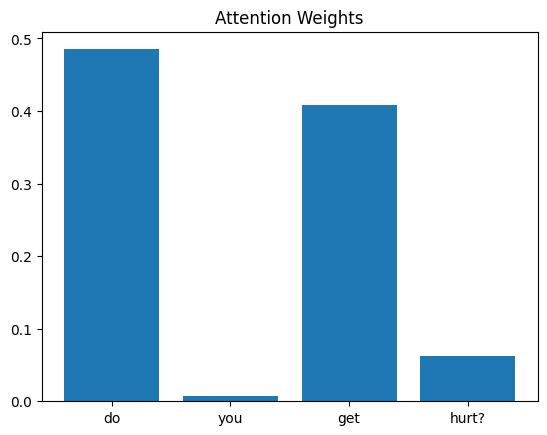

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

In [8]:
# Helper: run any question through the trained model and return its words, attention weights and answer
def get_attention(question_text):
    seq = tokenizer.texts_to_sequences([question_text.lower()])
    padded = pad_sequences(seq, maxlen=X.shape[1], padding="post")
    x = torch.tensor(padded, dtype=torch.long)

    with torch.no_grad():
        prediction, weights = model(x)

    words = [tokenizer.index_word[i] for i in seq[0]]                 # the words the model really sees
    word_weights = weights[0, :len(words)].tolist()                   # attention of the real words (not the padding)
    predicted_id = prediction.argmax(dim=1).item()
    predicted_answer = df[df["answer_id"] == predicted_id]["answer"].iloc[0]
    return words, word_weights, predicted_answer

Question: How old are you?
   Highest attention: 'are' (0.670)
   Model answer     : People created me.

Question: Who created you?
   Highest attention: 'who' (0.592)
   Model answer     : People created me.

Question: Do you have a name?
   Highest attention: 'name' (0.920)
   Model answer     : I'm better at answering questions.



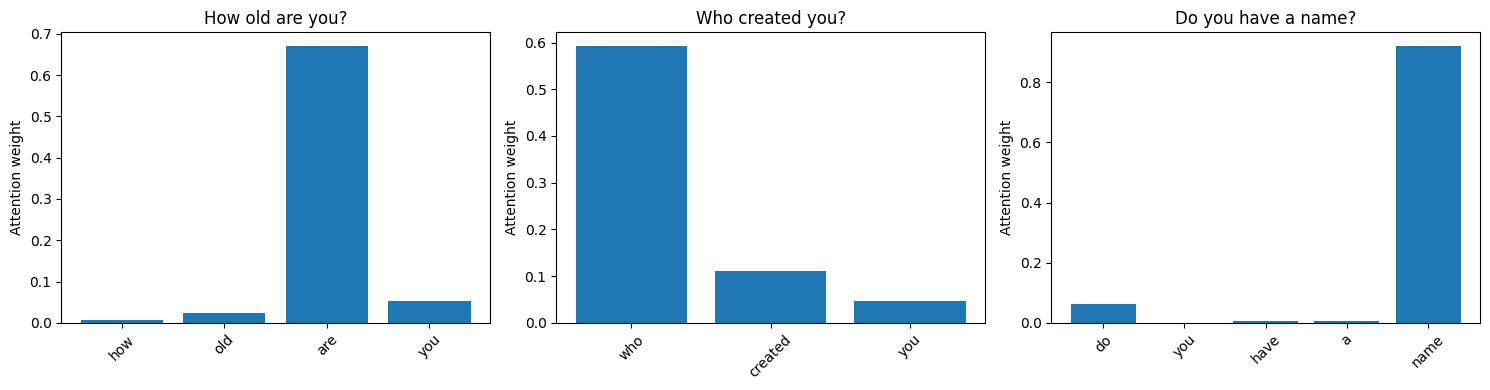

In [9]:
# Task 1: attention weights for three different questions
questions = ["How old are you?", "Who created you?", "Do you have a name?"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, q in zip(axes, questions):
    words, word_weights, answer = get_attention(q)

    ax.bar(words, word_weights)
    ax.set_title(q)
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=45)

    top_index = max(range(len(words)), key=lambda i: word_weights[i])
    print(f"Question: {q}")
    print(f"   Highest attention: '{words[top_index]}' ({word_weights[top_index]:.3f})")
    print(f"   Model answer     : {answer}\n")

plt.tight_layout()
plt.show()

**Answer (Task 1):**
Only partly. In some questions the word with the highest weight is a word that really carries the meaning of the question (for example "old", "created" or "name"), but in other questions the highest weight goes to a less meaningful word such as "you", "are" or "do". This is expected, because attention here is **not** designed to imitate human understanding: it is a set of weights that the model learned only to help it choose the right answer group. Also, this model is very small and is trained for only 50 steps on 168 questions, and the RNN reads the sentence from left to right, so the later words often carry more information about the whole sentence and tend to receive more attention. The weights also include the padding positions (the bars of the real words sum to less than 1). Look at your own charts and the printed "Highest attention" lines to confirm these observations for the three questions you chose.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: How old are you?
   Highest attention: 'are' (0.670)
   Model answer     : People created me.
Question: What's your age?
   Highest attention: 'age' (0.834)
   Model answer     : Not at all.


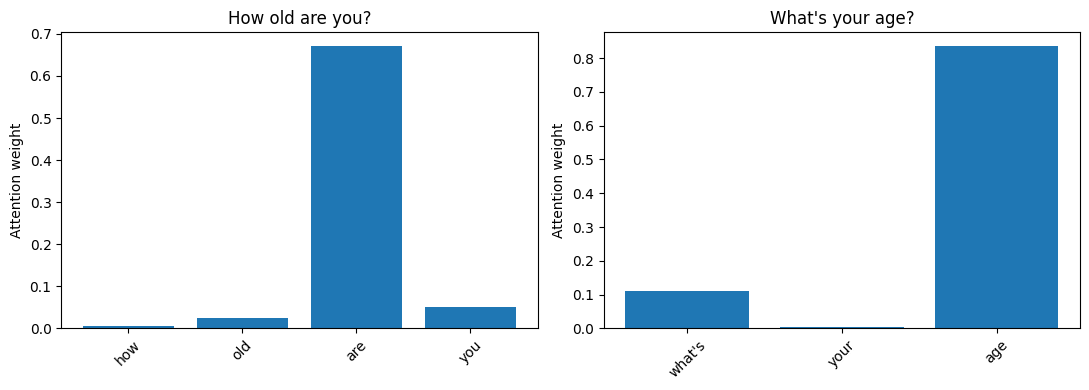

------------------------------------------------------------
Question: Who created you?
   Highest attention: 'who' (0.592)
   Model answer     : People created me.
Question: Which company made you?
   Highest attention: 'which' (0.526)
   Model answer     : People created me.


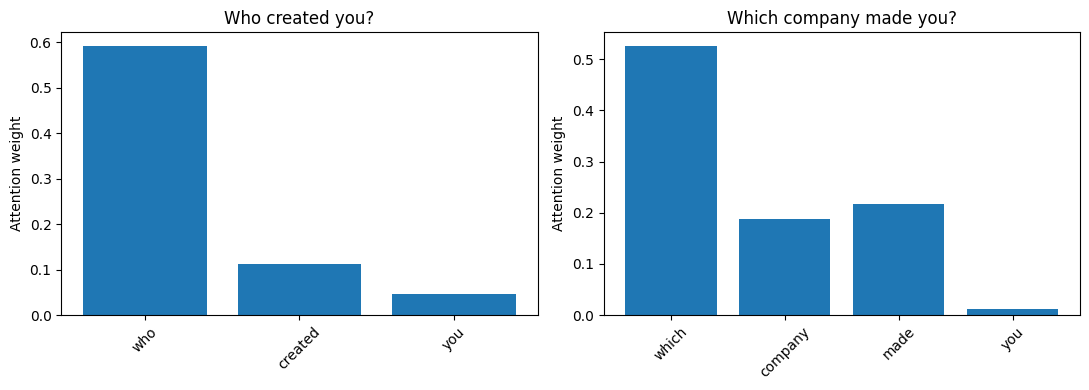

------------------------------------------------------------


In [10]:
# Task 2: compare attention for questions with a similar meaning but different wording
pairs = [
    ("How old are you?", "What's your age?"),            # both ask about age
    ("Who created you?", "Which company made you?"),    # both ask about the creator
]

for q1, q2 in pairs:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for ax, q in zip(axes, (q1, q2)):
        words, word_weights, answer = get_attention(q)

        ax.bar(words, word_weights)
        ax.set_title(q)
        ax.set_ylabel("Attention weight")
        ax.tick_params(axis="x", rotation=45)

        top_index = max(range(len(words)), key=lambda i: word_weights[i])
        print(f"Question: {q}")
        print(f"   Highest attention: '{words[top_index]}' ({word_weights[top_index]:.3f})")
        print(f"   Model answer     : {answer}")

    plt.tight_layout()
    plt.show()
    print("-" * 60)

**Answer (Task 2):**
The two questions in each pair have the same meaning (and should get the same answer), but the model does not necessarily focus on the same words. For "How old are you?" and "What's your age?", the highest weights can fall on different words ("old" vs "age"), because the words themselves are different. This suggests that attention does not store the meaning of the sentence: it only tells the model **where to look** inside the sentence. Each question is read through its own words, and the model learned that several different words ("old", "age", "born") can all lead to the same answer group. So the same prediction can be reached by attending to different words. When the two questions share some words (like "you"), those words may receive similar weights in both. Compare the printed top words and the charts above to see which case happened in your run.